In [ ]:
!pip install tensorflow==2.15.*

import matplotlib.pyplot as plt
import numpy as np
import os
import PIL
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.layers import Dense, Flatten, BatchNormalization
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
import cv2  # Only if you need OpenCV for image processing
import imghdr  # Optional, for image file type checking


In [ ]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip -n -qq "/content/drive/MyDrive/PlantDiseasesSplit.zip"

In [ ]:
# import os
# import shutil
# from sklearn.model_selection import train_test_split

# # Path to the original dataset
# train_folder = '/content//train'

# # Paths where you want to save the splits
# train_dest = '/content/Grapee/train'
# test_dest = '/content/Grapee/test'
# val_dest = '/content/Grapee/validation'

# # Create directories if they don't exist
# os.makedirs(train_dest, exist_ok=True)
# os.makedirs(test_dest, exist_ok=True)
# os.makedirs(val_dest, exist_ok=True)

# # Iterate over each class in the train folder (like "Black Rot", "ESCA", etc.)
# for class_folder in os.listdir(train_folder):
#     class_path = os.path.join(train_folder, class_folder)

#     if os.path.isdir(class_path):
#         # Get all images for this class
#         all_images = os.listdir(class_path)

#         # Split the images into 80% train, 20% test + validation
#         train_files, test_val_files = train_test_split(all_images, test_size=0.2, random_state=42)

#         # Further split the 20% into half (10% test, 10% validation)
#         test_files, val_files = train_test_split(test_val_files, test_size=0.5, random_state=42)

#         # Create class subdirectories in the train, test, and validation folders
#         os.makedirs(os.path.join(train_dest, class_folder), exist_ok=True)
#         os.makedirs(os.path.join(test_dest, class_folder), exist_ok=True)
#         os.makedirs(os.path.join(val_dest, class_folder), exist_ok=True)

#         # Function to move files
#         def move_files(files, source_dir, dest_dir, class_folder):
#             for file in files:
#                 src_path = os.path.join(source_dir, file)
#                 dst_path = os.path.join(dest_dir, file)
#                 shutil.move(src_path, dst_path)

#         # Move the files for each split
#         move_files(train_files, class_path, os.path.join(train_dest, class_folder), class_folder)
#         move_files(test_files, class_path, os.path.join(test_dest, class_folder), class_folder)
#         move_files(val_files, class_path, os.path.join(val_dest, class_folder), class_folder)

# print(f'Split done!')


In [ ]:
import os
import random
from PIL import Image
import shutil

# Set the paths
base_dir = '/content/Tomato'  # Replace with the correct path to your dataset
output_dir = '/content/Tomatoo'  # Directory to save resized and selected images

# Ensure the output directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)


In [ ]:
import os
import random
from PIL import Image

def resize_and_select_images(input_dir, output_dir, target_size=(256, 256), select_threshold=None):
    """
    Resizes images in the input directory to target_size and optionally selects a subset of images.
    """
    # Ensure the output directory exists
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    all_images = [f for f in os.listdir(input_dir) if os.path.isfile(os.path.join(input_dir, f))]

    # If a threshold is specified, select a random subset
    if select_threshold:
        selected_images = random.sample(all_images, min(select_threshold, len(all_images)))
    else:
        selected_images = all_images

    for image_name in selected_images:
        image_path = os.path.join(input_dir, image_name)
        output_path = os.path.join(output_dir, image_name)

        try:
            with Image.open(image_path) as img:
                img = img.resize(target_size)
                img.save(output_path)
        except Exception as e:
            print(f"Error processing {image_name}: {e}")

def process_dataset(base_dir, output_dir, target_size=(256, 256), select_threshold=1000):
    """
    Processes the dataset by resizing and selecting images for train, test, and validation directories.
    """
    # Process training set
    for split in ['train', 'test', 'valid']:
        input_split_dir = os.path.join(base_dir, split)
        output_split_dir = os.path.join(output_dir, split)

        if not os.path.exists(output_split_dir):
            os.makedirs(output_split_dir)

        for class_name in os.listdir(input_split_dir):
            input_class_dir = os.path.join(input_split_dir, class_name)
            output_class_dir = os.path.join(output_split_dir, class_name)

            if os.path.isdir(input_class_dir):
                # Adjust the threshold for test and valid sets
                if split == 'test' or split == 'valid':
                    threshold = int(select_threshold * 0.20)
                else:
                    threshold = select_threshold

                resize_and_select_images(input_class_dir, output_class_dir, target_size, threshold)


target_size = (256, 256)  # Set this to your desired resolution
select_threshold = 1000  # Number of images to select from training set

# Process the entire dataset (train, test, validation)
process_dataset(base_dir, output_dir, target_size, select_threshold)

print("Dataset processing complete.")


Dataset processing complete.


In [ ]:
image_exts = ['jpeg','jpg', 'bmp', 'png']

In [ ]:
data_dir='/content/Tomatoo/train'

In [ ]:
for image_class in os.listdir(data_dir):
    for image in os.listdir(os.path.join(data_dir, image_class)):
        image_path = os.path.join(data_dir, image_class, image)
        try:
            img = cv2.imread(image_path)
            tip = imghdr.what(image_path)
            if tip not in image_exts:
                print('Image not in ext list {}'.format(image_path))
                os.remove(image_path)
        except Exception as e:
            print('Issue with image {}'.format(image_path))
            os.remove(image_path)

In [ ]:
val_dir='/content/Tomatoo/valid'

In [ ]:
test_dir='/content/Tomatoo/test'

**PreProcessing the data**

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
# train_data = tf.keras.utils.image_dataset_from_directory(data_dir)
# valid_data=tf.keras.utils.image_dataset_from_directory(val_dir)

In [ ]:
# traindata_iterator = train_data.as_numpy_iterator()

In [ ]:
# batch = traindata_iterator.next()

In [ ]:
# fig, ax = plt.subplots(ncols=4, figsize=(20,20))
# for idx, img in enumerate(batch[0][:4]):
#     ax[idx].imshow(img.astype(int))
#     ax[idx].title.set_text(batch[1][idx])

In [ ]:
img_height,img_width=256,256
batch_size=16
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
  data_dir,
  #validation_split=0.2,
  seed=123,
  #subset="training",
  shuffle=True,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 10000 files belonging to 10 classes.


In [ ]:
# train_data = train_data.map(lambda x,y: (x/255, y))
# valid_data = valid_data.map(lambda x,y: (x/255, y))

In [ ]:
# train_data.as_numpy_iterator().next()
# valid_data.as_numpy_iterator().next()

In [ ]:

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
  val_dir,
  #validation_split=0.2,
  #subset="validation",
shuffle=True,
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 2000 files belonging to 10 classes.


In [ ]:
test_ds = tf.keras.preprocessing.image_dataset_from_directory(
  test_dir,
shuffle=True,
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 2000 files belonging to 10 classes.


In [ ]:
class_names=train_ds.class_names
class_names

['Tomato_Bacterial_spot',
 'Tomato_Early_blight',
 'Tomato_Healthy',
 'Tomato_Late_blight',
 'Tomato_Leaf_Mold',
 'Tomato_Mosaic_virus',
 'Tomato_Septoria_leaf_spot',
 'Tomato_Spider_mites',
 'Tomato_Target_Spot',
 'Tomato_Yellow_Leaf_Curl_Virus']

**Visualizing Some of the images**

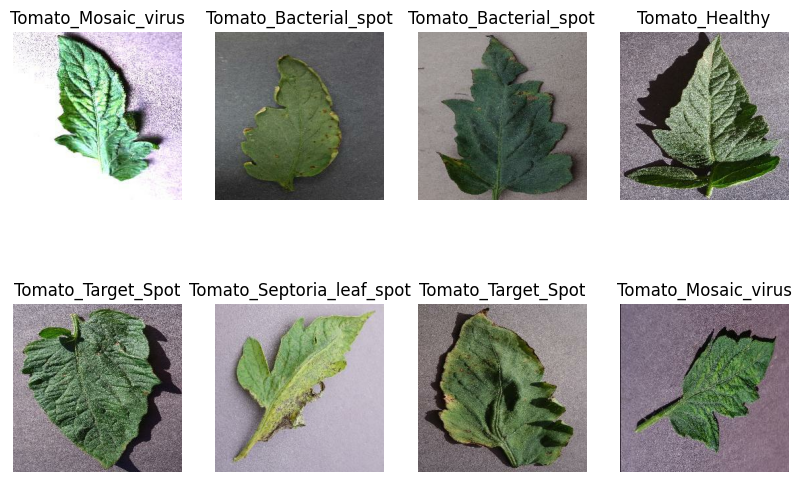

In [ ]:
plt.figure(figsize=(10, 10))
for image_batch, labels_batch in train_ds.take(1):
    for i in range(8):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[labels_batch[i]])
        plt.axis("off")

In [ ]:
# train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
# val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
# test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

In [ ]:
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(256, 256),
    layers.Rescaling(1./255),
])

In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
])

In [ ]:
train_ds = (
    train_ds
    .shuffle(buffer_size=100)  # Reduced shuffle buffer size for memory efficiency
    # .map(lambda x, y: (resize_and_rescale(x), y))  # Apply resizing and rescaling
    .map(lambda x, y: (data_augmentation(x, training=True), y))  # Apply data augmentation
    .prefetch(buffer_size=tf.data.AUTOTUNE)  # Prefetch to optimize memory usage and performance
)

# Optimize the validation dataset pipeline
val_ds = (
    val_ds
    # .map(lambda x, y: (resize_and_rescale(x), y))  # Apply resizing and rescaling
    .map(lambda x, y: (data_augmentation(x, training=True), y))
    .prefetch(buffer_size=tf.data.AUTOTUNE)  # Prefetch for optimization
)

In [ ]:
resnet_model = Sequential()

In [ ]:
earlystopping = callbacks.EarlyStopping(monitor="val_loss",
                                        mode="min", patience=5,
                                        restore_best_weights=True)

In [ ]:
pretrained_model = tf.keras.applications.ResNet50(
    include_top=False,
    input_shape=(256, 256, 3),
    pooling='max',
    weights='imagenet',
    classes=10
)


In [ ]:
pretrained_model.output

<KerasTensor: shape=(None, 2048) dtype=float32 (created by layer 'max_pool')>

In [ ]:
for layer in pretrained_model.layers:
        layer.trainable=False

In [ ]:
resnet_model.add(pretrained_model)
resnet_model.add(BatchNormalization())
resnet_model.add(Flatten())
resnet_model.add(layers.Dense(128, activation='relu'))
resnet_model.add(layers.Dense(64, activation='relu'))
resnet_model.add(layers.Dense(32, activation='relu'))
resnet_model.add(layers.Dense(16, activation='relu'))

resnet_model.add(layers.Dense(10, activation='softmax'))



# x = keras.layers.Flatten()(pretrained_model.output)
# x = keras.layers.Dense(256, activation='relu')(x)
# x = keras.layers.Dense(128, activation='relu')(x)
# x = keras.layers.Dense(64, activation='relu')(x)
# predictions = keras.layers.Dense(3, activation='softmax')(x)
# full_model = keras.models.Model(inputs=pretrained_model.input, outputs=predictions)
# full_model.summary()



In [ ]:
resnet_model.summary()

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 resnet50 (Functional)       (None, 2048)              23587712  
                                                                 
 batch_normalization (Batch  (None, 2048)              8192      
 Normalization)                                                  
                                                                 
 flatten_1 (Flatten)         (None, 2048)              0         
                                                                 
 dense_5 (Dense)             (None, 128)               262272    
                                                                 
 dense_6 (Dense)             (None, 64)                8256      
                                                                 
 dense_7 (Dense)             (None, 32)                2080      
                                                      

In [ ]:
resnet_model.compile(optimizer=Adam(learning_rate=0.001),loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),metrics=['accuracy'])



In [ ]:
epochs=50
with tf.device('/GPU:0'):  # Replace with '/GPU:1', '/GPU:2', etc., for multiple GPUs
    history = resnet_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=[earlystopping]
    )


Epoch 1/50
625/625 [==============================] - 138s 207ms/step - loss: 0.7624 - accuracy: 0.7479 - val_loss: 0.3830 - val_accuracy: 0.8750
Epoch 2/50
625/625 [==============================] - 128s 202ms/step - loss: 0.4074 - accuracy: 0.8646 - val_loss: 0.3082 - val_accuracy: 0.9015
Epoch 3/50
625/625 [==============================] - 128s 203ms/step - loss: 0.3269 - accuracy: 0.8922 - val_loss: 0.3004 - val_accuracy: 0.8995
Epoch 4/50
625/625 [==============================] - 129s 204ms/step - loss: 0.3027 - accuracy: 0.8985 - val_loss: 0.2419 - val_accuracy: 0.9295
Epoch 5/50
625/625 [==============================] - 134s 213ms/step - loss: 0.2618 - accuracy: 0.9116 - val_loss: 0.2064 - val_accuracy: 0.9385
Epoch 6/50
625/625 [==============================] - 152s 241ms/step - loss: 0.2333 - accuracy: 0.9227 - val_loss: 0.1923 - val_accuracy: 0.9415
Epoch 7/50
625/625 [==============================] - 150s 238ms/step - loss: 0.2373 - accuracy: 0.9222 - val_loss: 0.2085 -

In [ ]:
# Save the entire model as a .h5 file
model_filename = 'Grape.h5'
resnet_model.save(model_filename)


/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [ ]:
from google.colab import files

# Download the model file
files.download(model_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
history.history['val_loss']

[0.38296326994895935,
 0.30823105573654175,
 0.3004465699195862,
 0.24186182022094727,
 0.20640674233436584,
 0.1923338919878006,
 0.20853982865810394,
 0.24863483011722565,
 0.21026252210140228,
 0.17759771645069122,
 0.1749381273984909,
 0.15712524950504303,
 0.15416908264160156,
 0.16105376183986664,
 0.18711498379707336,
 0.14538386464118958,
 0.15473045408725739,
 0.13078650832176208,
 0.15765298902988434,
 0.13437676429748535,
 0.1402367651462555,
 0.13856424391269684,
 0.1528252512216568]

In [ ]:
history.history['loss']

[0.7623864412307739,
 0.407400906085968,
 0.3269032835960388,
 0.302735298871994,
 0.26176926493644714,
 0.23327785730361938,
 0.23728986084461212,
 0.22003965079784393,
 0.22335031628608704,
 0.19877952337265015,
 0.18542733788490295,
 0.18407535552978516,
 0.16509784758090973,
 0.16528956592082977,
 0.17436279356479645,
 0.166202574968338,
 0.15017296373844147,
 0.1559813767671585,
 0.13971111178398132,
 0.13858802616596222,
 0.14320868253707886,
 0.1292293518781662,
 0.13632537424564362]

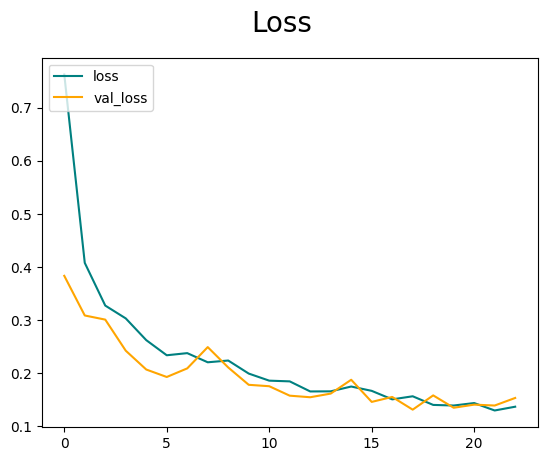

In [ ]:
fig = plt.figure()
plt.plot(history.history['loss'], color='teal', label='loss')
plt.plot(history.history['val_loss'], color='orange', label='val_loss')
fig.suptitle('Loss', fontsize=20)
plt.legend(loc="upper left")
plt.show()

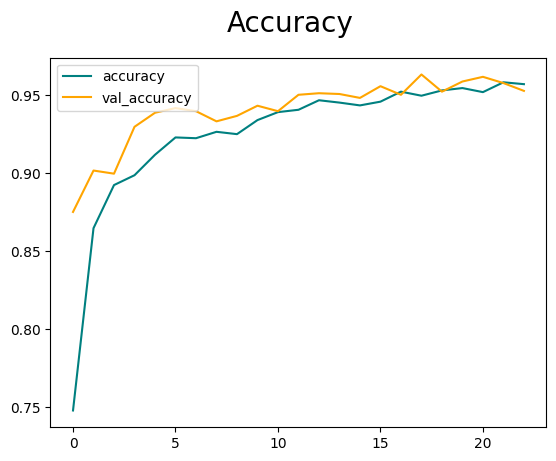

In [ ]:
fig = plt.figure()
plt.plot(history.history['accuracy'], color='teal', label='accuracy')
plt.plot(history.history['val_accuracy'], color='orange', label='val_accuracy')
fig.suptitle('Accuracy', fontsize=20)
plt.legend(loc="upper left")
plt.show()

In [ ]:
import cv2
class_names=['Peach_Bacterial_spot', 'Peach_Healthy']

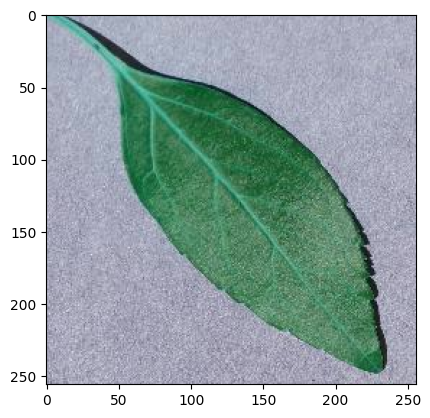

In [ ]:
img = cv2.imread('/content/Peach/test/Peach_Bacterial_spot/PeachBacterialSpot(2550).JPG')
#img=cv2.imread('LATE2.jpeg')

plt.imshow(img)
plt.show()

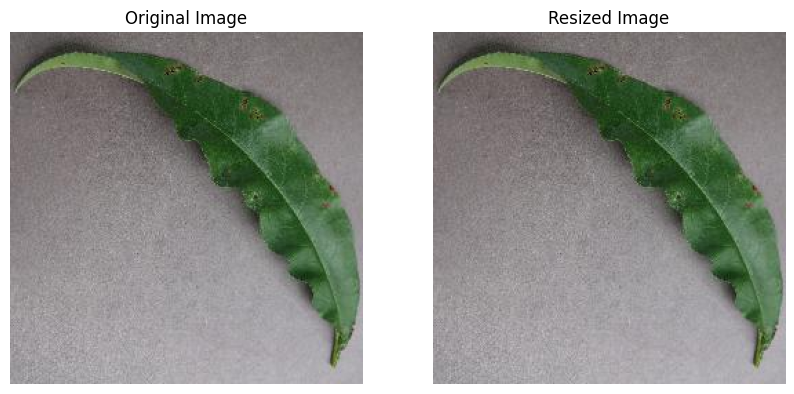

In [ ]:
import cv2
from google.colab import files
import matplotlib.pyplot as plt


# Choose the desired new width (you can adjust this)
new_width = 256

# Function to resize image while maintaining aspect ratio
def resize_image_with_aspect_ratio(image, new_width):


    # Calculate the aspect ratio
    aspect_ratio = img.shape[1] / img.shape[0]

    # Calculate the new height based on the aspect ratio
    new_height = int(new_width / aspect_ratio)

    # Resize the image
    resized_img = cv2.resize(img, (new_width, new_height))

    return resized_img

# Choose the uploaded image file (update the filename accordingly)
image = img

# Resize the image
resized_image = resize_image_with_aspect_ratio(image, new_width)

# Display the original and resized images
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Resized Image
plt.subplot(1, 2, 2)
plt.title("Resized Image")
plt.imshow(cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()


(256, 256, 3)


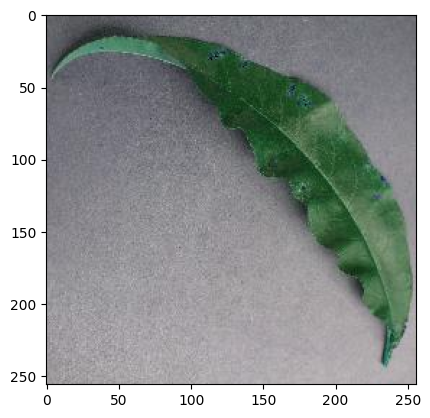

In [ ]:
resize= cv2.resize(img, (256,256))
print(resize.shape)
#plt.imshow(resize.numpy().astype(int))
plt.imshow(resize)
plt.show()

In [ ]:
yhat = resnet_model.predict(np.expand_dims(resized_image, 0))

1/1 [==============================] - 1s 1s/step


In [ ]:
yhat

array([[1.00000e+00, 6.86396e-23]], dtype=float32)

In [ ]:
output_class=class_names[np.argmax(yhat)]
print("The predicted class is", output_class)

The predicted class is Cherry_Healthy


In [ ]:
# Assuming 'model' is your trained model
loss, accuracy = resnet_model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

NameError: name 'resnet_model' is not defined

1/1 [==============================] - 0s 29ms/step
Confusion Matrix:
[[200   0]
 [  0 200]]

Classification Report:
                        precision    recall  f1-score   support

    Strawberry_Healthy       1.00      1.00      1.00       200
Strawberry_Leaf_scorch       1.00      1.00      1.00       200

              accuracy                           1.00       400
             macro avg       1.00      1.00      1.00       400
          weighted avg       1.00      1.00      1.00       400



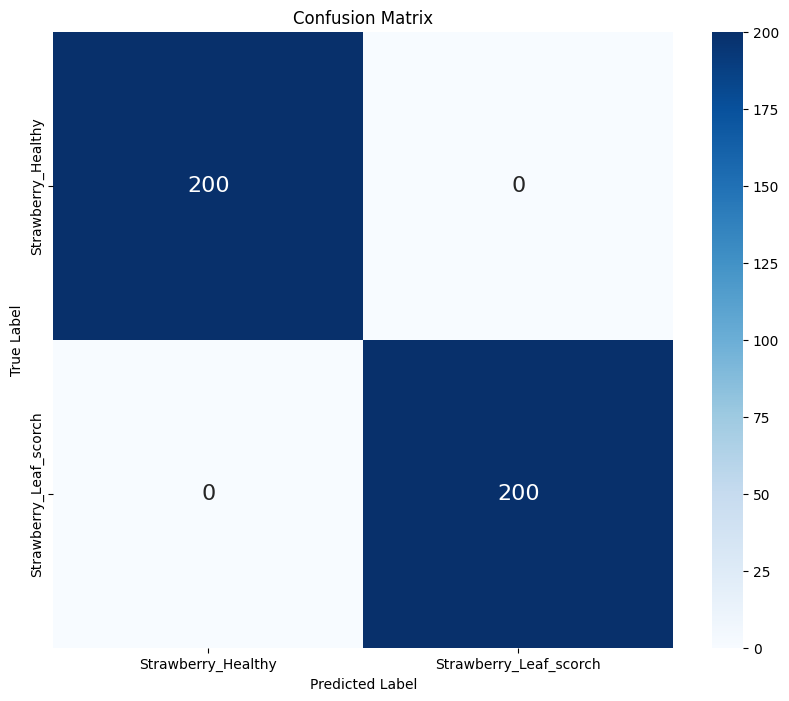

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import os

 # Replace with your actual class names

# Lists to hold true labels and predictions
y_true = []
y_pred = []

# Iterate through the test dataset
for images, labels in test_ds:
    # Make predictions
    predictions = resnet_model.predict(images, batch_size=batch_size)

    # Convert predictions to class indices
    predicted_classes = np.argmax(predictions, axis=1)

    # Convert labels tensor to numpy array and then to list
    true_classes = labels.numpy()  # Directly use if labels are integer encoded

    # Append results to lists
    y_pred.extend(predicted_classes)
    y_true.extend(true_classes)

# Convert lists to numpy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Generate confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Generate classification report
class_report = classification_report(y_true, y_pred, target_names=class_names)

# Print confusion matrix and classification report
print("Confusion Matrix:")
print(conf_matrix)

print("\nClassification Report:")
print(class_report)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, annot_kws={"size": 16})
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
pre = Precision()
re = Recall()
acc = BinaryAccuracy()

In [ ]:
len(test_data)

1

In [ ]:
test_data=test_data.take(1)

In [ ]:
for batch in test_data.as_numpy_iterator():
    X, y = batch
    yhat=model.predict()
    print(y)

[0 1 2 2 1 0 1 2 0 0 1 1 1 0 2 0 1 2 2 1 2 2 1 1 2 1 0 0 2 0 0 2]


In [ ]:
from tensorflow.keras.models import load_model

In [ ]:
resnet_model.save('model')

In [ ]:
!zip -r model.zip model

  adding: model/ (stored 0%)
  adding: model/fingerprint.pb (stored 0%)
  adding: model/saved_model.pb (deflated 91%)
  adding: model/variables/ (stored 0%)
  adding: model/variables/variables.data-00000-of-00001 (deflated 8%)
  adding: model/variables/variables.index (deflated 78%)
  adding: model/keras_metadata.pb (deflated 96%)
  adding: model/assets/ (stored 0%)


In [ ]:
resnet_model.save('myleaf.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


NotImplementedError: ignored

OSError: ignored